# 第 10 课｜正态分布与金融

> **数据身份**：固定随机种子生成的模拟教学数据，不是真实证券行情。  
> **环境**：`pkm-quant` · Python 3.11 · 默认离线运行。  
> **课程原始材料**：`10_youtube-pQir11RK3Lw/index.html`  
> **所属模块**：P1-M3 · 统计证据与可预测性

## 本节量化问题

为什么正态分布仍是有用基准，却不能当作真实收益定律？

## 准确定义与策略报告位置

正态分布由均值和方差刻画，便于建立基准概率和误差模型；真实金融收益常有偏度、厚尾和波动聚集。

- **核心关系**：Z=(X-μ)/σ；正态密度由均值 μ 和标准差 σ 决定。
- **写入报告**：分布假设和基准风险模型
- **P2 衔接**：P2 第 48 课：SciPy 分布与极端风险。


## 运行环境与数据契约

先确认项目、数据目录和数据身份。后续联网数据源必须通过适配层进入，不能改变本 Notebook 的研究计算口径。

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "data" / "fixtures").exists():
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data" / "fixtures"
OUTPUT_DIR = ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

RANDOM_SEED = 365
print("项目:", ROOT)
print("数据:", DATA_DIR)
print("数据身份: 固定随机种子生成的模拟教学数据，不是真实证券行情")


项目: /Users/mojiawen/Documents/学习资料归档/_暂存/personal_knowledge_manager/量化交易/实验/p1-quant-foundations
数据: /Users/mojiawen/Documents/学习资料归档/_暂存/personal_knowledge_manager/量化交易/实验/p1-quant-foundations/data/fixtures
数据身份: 固定随机种子生成的模拟教学数据，不是真实证券行情


## 把正态分布当作基准而不是事实

使用样本均值和标准差构造同参数正态基准，再比较偏度、峰度与正态性检验。

In [2]:
from scipy import stats

daily = pd.read_csv(DATA_DIR / "daily_prices.csv", parse_dates=["date"])
market = daily.loc[daily["symbol"] == "SIM_MARKET"].set_index("date")["adj_close"]
returns = market.pct_change(fill_method=None).dropna()

mu, sigma = returns.mean(), returns.std(ddof=1)
jb = stats.jarque_bera(returns)
diagnostics = pd.Series({
    "mean": mu,
    "std": sigma,
    "skew": stats.skew(returns, bias=False),
    "excess_kurtosis": stats.kurtosis(returns, fisher=True, bias=False),
    "jarque_bera_pvalue": jb.pvalue,
})
display(diagnostics)

mean                 -0.000012
std                   0.008774
skew                  0.021000
excess_kurtosis       0.367601
jarque_bera_pvalue    0.130688
dtype: float64

## 比较经验直方图与正态密度

横轴是日收益，纵轴是密度；拟合曲线只说明中心区域的基准形状。

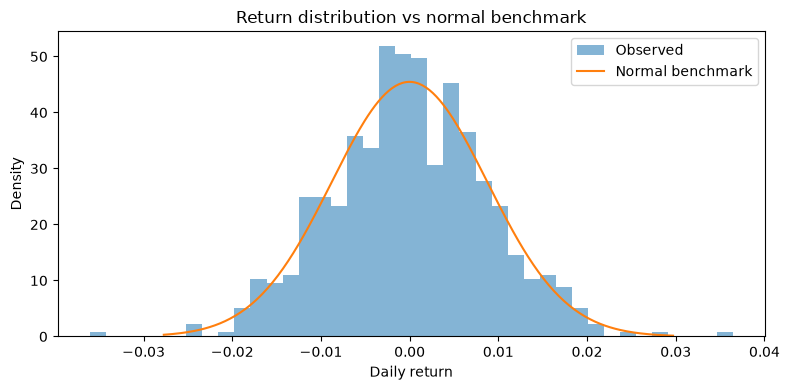

In [3]:
x = np.linspace(returns.quantile(0.001), returns.quantile(0.999), 300)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(returns, bins=40, density=True, alpha=0.55, label="Observed")
ax.plot(x, stats.norm.pdf(x, mu, sigma), label="Normal benchmark")
ax.set(title="Return distribution vs normal benchmark", xlabel="Daily return", ylabel="Density")
ax.legend()
plt.tight_layout()
plt.show()

## 方法边界与阶段验收

正态拟合良好不等于极端风险可靠；尾部结论必须单独检查。

完成本课后应能：

1. 不看课程材料准确解释核心概念和公式符号；
2. 用小样本手工核对 Notebook 的关键结果；
3. 说明结果能支持什么判断、不能支持什么判断；
4. 指出它在策略报告中的位置，以及仍缺少的数据、成本或稳健性证据。
